# CuZn order-disorder transition: Metropolis analysis

This notebook uses the rigid-lattice Monte Carlo model of `src/model.py`:

- bcc lattice of $6 \times 6 \times 6$ cells, $N = 432$ sites, periodic boundary conditions;
- pair energies $J$ (1st neighbours) and $I$ (2nd neighbours) from the project description;
- Metropolis algorithm with exchanges of two 1st-neighbour atoms.

Units: energies in eV, temperatures in K.
One **sweep** = $N = 432$ exchange attempts (each atom gets on average one chance to move). The functions of `model.py` count in **steps** (single attempts), so we pass `n_sweeps * SWEEP`.

Plan:
1. checks at $T = 0$ K and cohesive energy;
2. number of steps needed to reach equilibrium (`metropolis_before_eq`);
3. temperature scan with `metropolis`: energy, heat capacity, long-range order $\eta$, Cowley parameters $\alpha_1, \alpha_2$;
4. estimate of the transition temperature.

In [30]:
import sys
import random

import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "src")
import model

random.seed(2026)     # model.py uses the global random module: fixed seed = reproducible notebook
np.random.seed(2026)  # used below to build random (fully disordered) lattices

N = model.NB_SITES
SWEEP = model.NB_SITES  # 1 sweep = NB_SITES exchange attempts

## 4. Checks at $T = 0$ K and cohesive energy

At $T = 0$ K the structure is the perfect B2 order (Cu on the corners $\alpha$, Zn on the centres $\beta$).
Each atom has 8 first neighbours, all of the other species, and its 6 second neighbours are of its own species ($I_{\text{CuCu}} = I_{\text{ZnZn}} = 0$). Counting each pair once:

$$\frac{E}{N} = \frac{8}{2} J_{\text{CuZn}} = 4 \times (-0.621) = -2.484 \text{ eV/atom}$$

We also expect $\alpha_1 = -1$ (only Zn around a Cu), $\alpha_2 = +1$ (no Zn in the second shell) and $\eta = 1$.

In [31]:
model.init_at_t0()
E0 = model.get_full_energy()
alpha_1, alpha_2 = model.cowley()
eta = model.order_parameter()

print(f"E(B2) = {E0:.3f} eV for {N} atoms")
print(f"Cohesive energy at T = 0 K: {E0 / N:.4f} eV/atom")
print(f"Cowley parameters: alpha_1 = {alpha_1:+.3f}, alpha_2 = {alpha_2:+.3f}  (expected -1, +1)")
print(f"Long-range order parameter: eta = {eta:.3f}  (expected 1)")

assert abs(E0 / N + 2.484) < 1e-9
assert abs(alpha_1 + 1) < 1e-12 and abs(alpha_2 - 1) < 1e-12 and eta == 1

E(B2) = -1073.088 eV for 432 atoms
Cohesive energy at T = 0 K: -2.4840 eV/atom
Cowley parameters: alpha_1 = -1.000, alpha_2 = +1.000  (expected -1, +1)
Long-range order parameter: eta = 1.000  (expected 1)


## 2. Number of steps needed to reach equilibrium

`metropolis` starts from the perfect B2 structure, so the first steps are not representative of the temperature $T$: the system needs some time to "forget" its initial state.
For several temperatures we run `metropolis_before_eq` for a long time (the run is longer at low temperature, where the dynamics is slower). It returns the energy after every step, and we look at when the energy stops drifting and only fluctuates around a constant value:
- the convergence value $E_{eq}$ and the size $\sigma$ of the fluctuations are the mean and standard deviation over the second half of the run (red dotted line);
- equilibrium is reached at the first step where $E \geq E_{eq} - \sigma$ (black dotted line).

T =   300 K: E_eq = -2.4840 eV/atom, equilibrium reached after 0 steps
T =   600 K: E_eq = -2.4718 eV/atom, equilibrium reached after 9809 steps
T =   700 K: E_eq = -2.4600 eV/atom, equilibrium reached after 4690 steps
T =   800 K: E_eq = -2.4523 eV/atom, equilibrium reached after 3451 steps
T =   900 K: E_eq = -2.4509 eV/atom, equilibrium reached after 3017 steps
T =  1000 K: E_eq = -2.4499 eV/atom, equilibrium reached after 2493 steps
T =  1100 K: E_eq = -2.4493 eV/atom, equilibrium reached after 1680 steps
T =  1200 K: E_eq = -2.4491 eV/atom, equilibrium reached after 1258 steps


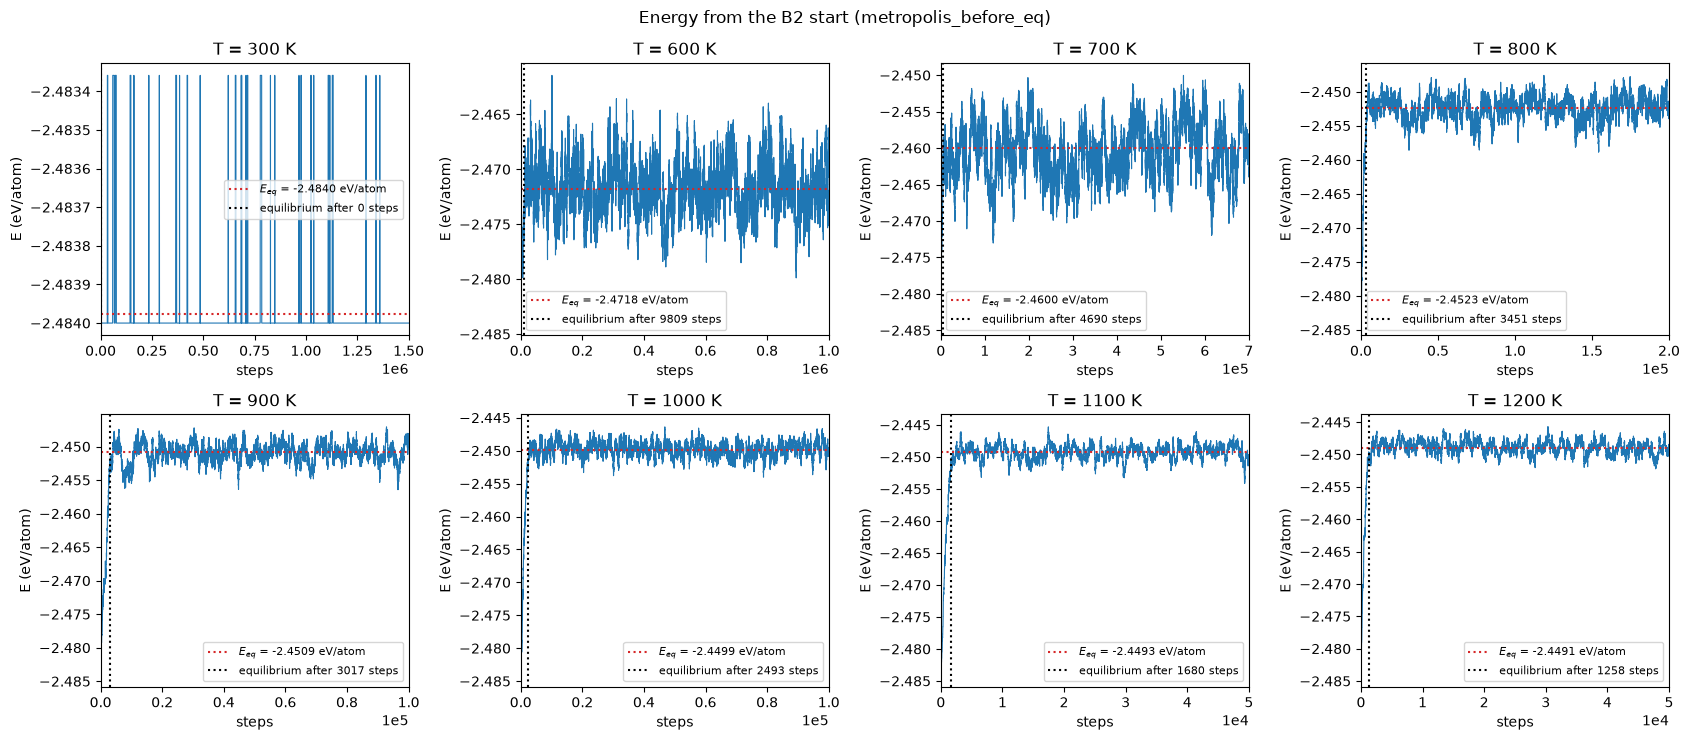

In [32]:
def plot_relaxation(ax, T, n_steps):
    # Energy from the B2 start, with the convergence value and the step where equilibrium is reached
    energies = np.array(model.metropolis_before_eq(n_steps, T)) / N  # eV/atom, one value per step
    E_eq = energies[n_steps // 2:].mean()  # convergence value: mean over the second half of the run
    sigma = energies[n_steps // 2:].std()  # size of the equilibrium fluctuations
    n_eq = int(np.argmax(energies >= E_eq - sigma))  # first step inside the equilibrium fluctuations
    print(f"T = {T:5d} K: E_eq = {E_eq:.4f} eV/atom, equilibrium reached after {n_eq} steps")
    ax.plot(energies, lw=0.8)
    ax.axhline(E_eq, color="C3", ls=":", lw=1.5, label=f"$E_{{eq}}$ = {E_eq:.4f} eV/atom")
    ax.axvline(n_eq, color="k", ls=":", lw=1.5, label=f"equilibrium after {n_eq} steps")
    ax.legend(fontsize=8)
    ax.set_title(f"T = {T} K")
    ax.set_xlabel("steps")
    ax.set_ylabel("E (eV/atom)")
    ax.set_xlim(0, n_steps)
    ax.ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
    ax.ticklabel_format(axis="y", useOffset=False)


T_EQ = [300, 600, 700, 800, 900, 1000, 1100, 1200]  # K
N_STEPS_TEST = [1500000, 1000000, 700000, 200000, 100000, 100000, 50000, 50000]  # steps

fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
for ax, T, n_steps in zip(axes.flat, T_EQ, N_STEPS_TEST):
    plot_relaxation(ax, T, n_steps)
fig.suptitle("Energy from the B2 start (metropolis_before_eq)")
fig.tight_layout()
plt.show()

The energy starts at the B2 value $-2.484$ eV/atom and increases until it fluctuates around its equilibrium value.
At low temperature the B2 start is already (almost) at equilibrium; at high temperature the disorder sets in within a few thousand steps. The slowest relaxation is at intermediate temperatures, below the transition, but in every case equilibrium is reached in less than 10000 steps.

We therefore use `N_EQ` = 20000 steps of equilibration (twice the slowest relaxation, to be safe) for every temperature of the scan, and check it below on all the temperatures of the scan.

T =   200 K: E_eq = -2.4840 eV/atom, equilibrium reached after 0 steps
T =   300 K: E_eq = -2.4840 eV/atom, equilibrium reached after 0 steps
T =   400 K: E_eq = -2.4837 eV/atom, equilibrium reached after 0 steps
T =   500 K: E_eq = -2.4783 eV/atom, equilibrium reached after 22091 steps
T =   550 K: E_eq = -2.4760 eV/atom, equilibrium reached after 5888 steps
T =   600 K: E_eq = -2.4733 eV/atom, equilibrium reached after 3578 steps
T =   650 K: E_eq = -2.4672 eV/atom, equilibrium reached after 4003 steps
T =   675 K: E_eq = -2.4646 eV/atom, equilibrium reached after 3884 steps
T =   700 K: E_eq = -2.4645 eV/atom, equilibrium reached after 2709 steps
T =   710 K: E_eq = -2.4586 eV/atom, equilibrium reached after 8146 steps
T =   720 K: E_eq = -2.4579 eV/atom, equilibrium reached after 7181 steps
T =   730 K: E_eq = -2.4602 eV/atom, equilibrium reached after 6992 steps
T =   740 K: E_eq = -2.4548 eV/atom, equilibrium reached after 9453 steps
T =   750 K: E_eq = -2.4566 eV/atom, equilibri

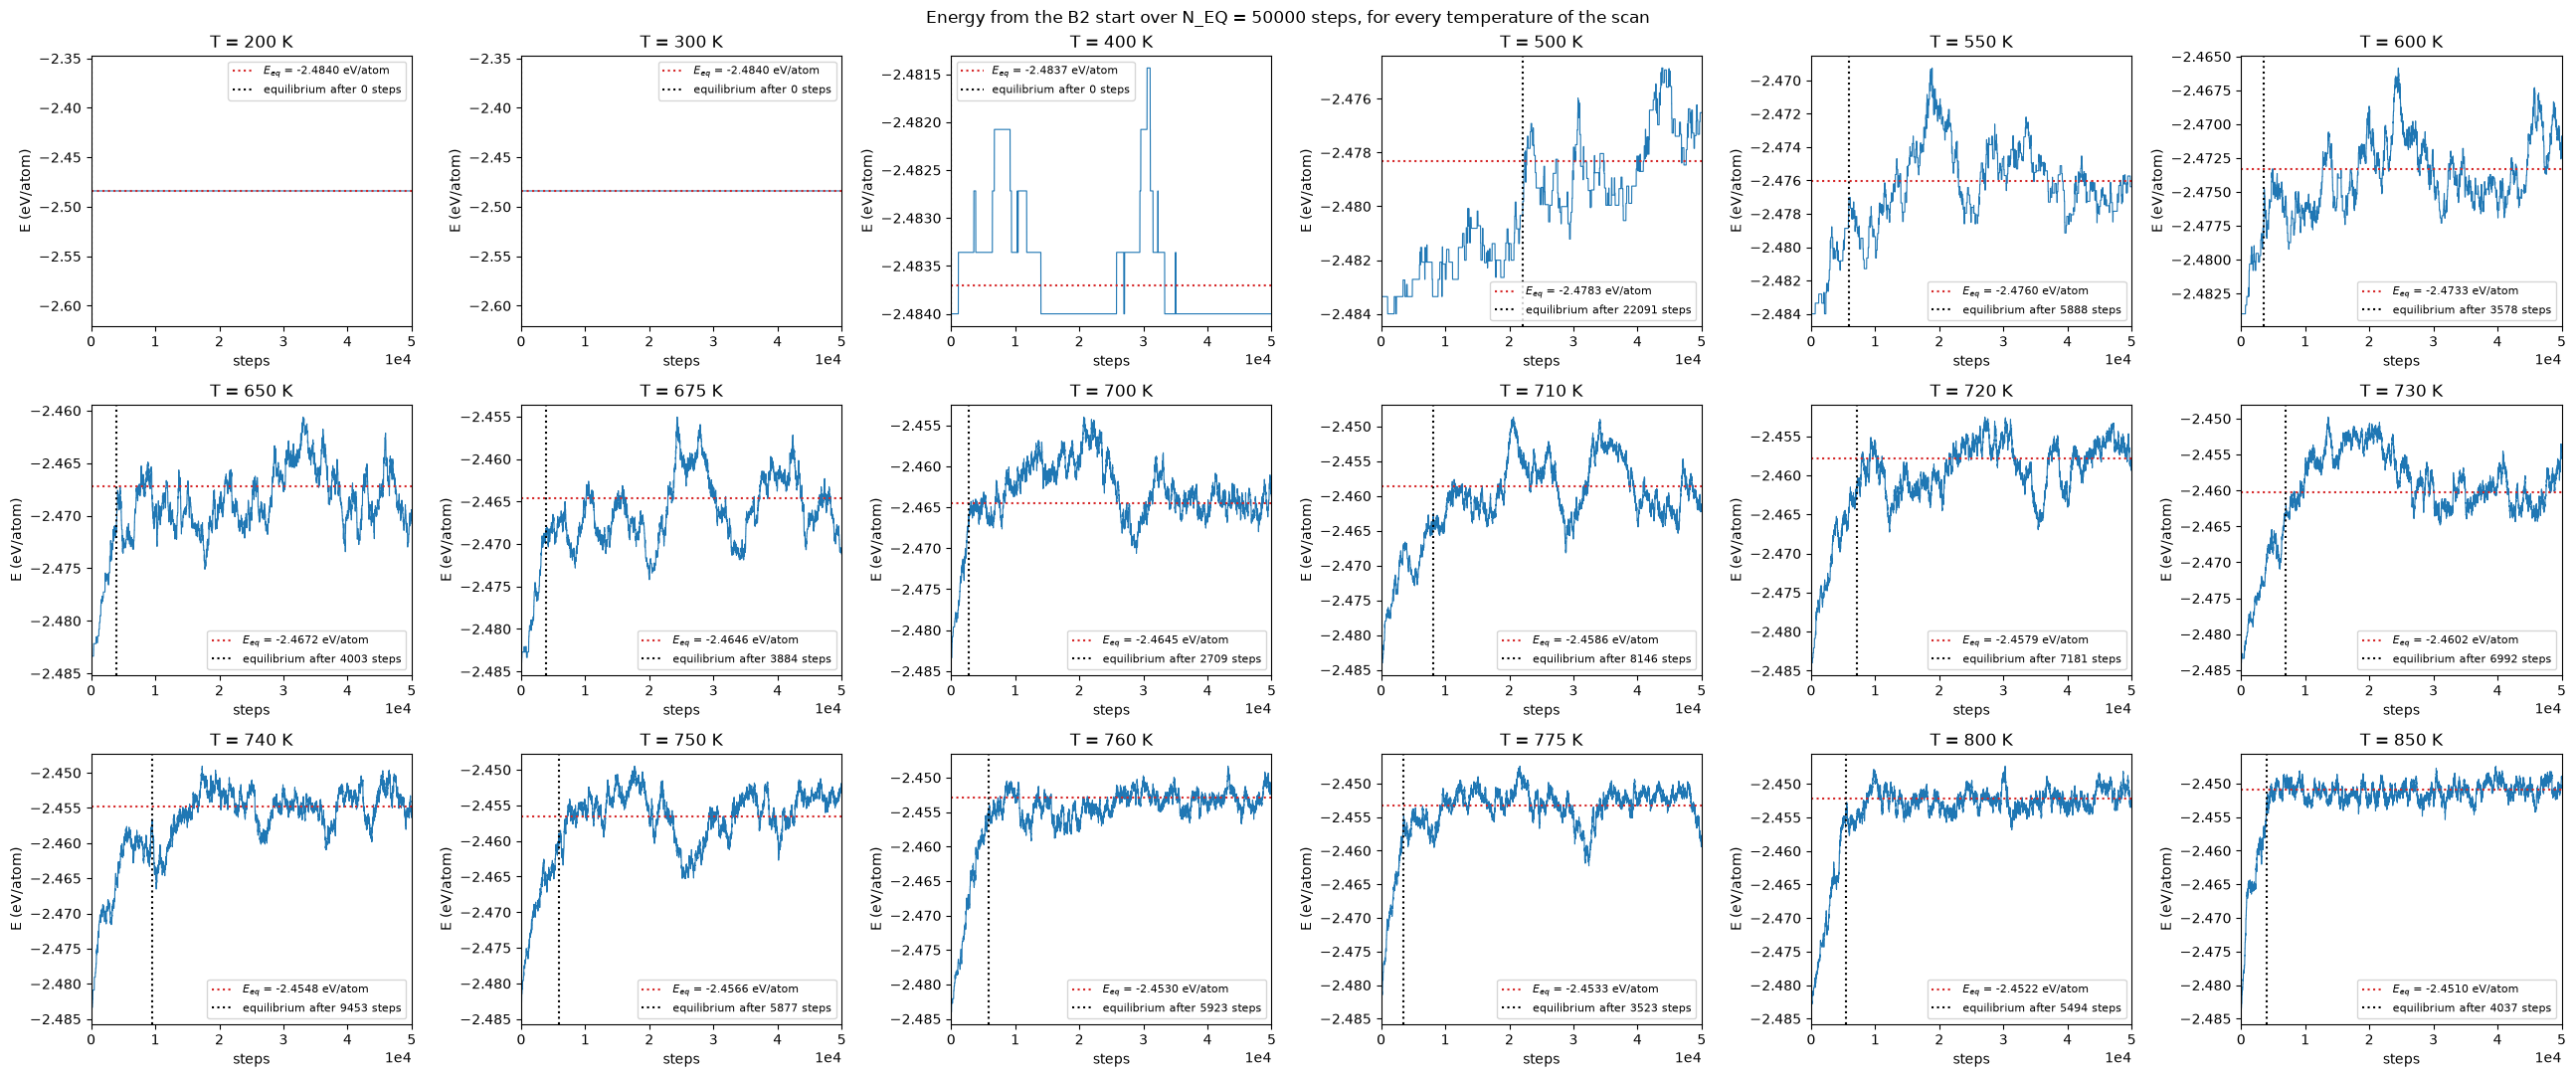

In [33]:
T_SCAN = [200, 300, 400, 500, 550, 600, 650, 675, 700, 710, 720, 730, 740, 750, 760, 775, 800, 850, 900, 1000, 1200, 1600]  # K
N_EQ = 50000  # steps of equilibration for every temperature of the scan

fig, axes = plt.subplots(3, 6, figsize=(26, 11))
for ax, T in zip(axes.flat, T_SCAN):
    plot_relaxation(ax, T, N_EQ)
fig.suptitle(f"Energy from the B2 start over N_EQ = {N_EQ} steps, for every temperature of the scan")
fig.tight_layout()
plt.show()

## 3. Temperature scan

For each temperature, `metropolis` runs `N_EQ` steps without measuring, then `N_MEAS` sweeps with one measurement per sweep (`measure_every=SWEEP`). Consecutive steps differ by at most two atoms, so measuring more often would cost a lot of time without adding information. The whole scan takes a few minutes.

From the measured series we compute:
- the mean energy per atom $\langle E \rangle / N$;
- the heat capacity per atom from the energy fluctuations, in units of $k_B$: $\dfrac{C}{N k_B} = \dfrac{\langle E^2 \rangle - \langle E \rangle^2}{N (k_B T)^2}$;
- $\langle |\eta| \rangle$ and $\langle \eta^2 \rangle$ (the absolute value is needed because near $T_c$ the order can flip between "Cu on $\alpha$" and "Cu on $\beta$");
- the susceptibility of the order parameter from the fluctuations of $|\eta|$, in $eV^{-1}$: $\chi = \dfrac{N \left( \langle \eta^2 \rangle - \langle |\eta| \rangle^2 \right)}{k_B T}$. It is the response $\partial \langle \eta \rangle / \partial h$ to a field $h$ favouring Cu on $\alpha$ (fluctuation-dissipation, like $C$ for the energy). We use $|\eta|$ because in a finite box $\langle \eta \rangle = 0$ (the order flips between $\alpha$ and $\beta$), so $\langle \eta^2 \rangle - \langle \eta \rangle^2$ would not peak at $T_c$;
- $\langle \alpha_1 \rangle$, $\langle \alpha_2 \rangle$.

Error bars are $\sigma / \sqrt{n}$ over the measurements. Consecutive sweeps are correlated, so they underestimate the real uncertainty, especially near $T_c$.

In [ ]:
N_MEAS = 800

series = {}
for T in T_SCAN:
    series[T] = model.metropolis(N_EQ, N_MEAS * SWEEP, T, measure_every=SWEEP)
    energies, eta, alpha_1, alpha_2 = series[T]
    print(f"T = {T:5d} K: E = {energies.mean() / N:.4f} eV/atom, |eta| = {eta.mean():.3f}, "
          f"alpha_1 = {alpha_1.mean():+.3f}, alpha_2 = {alpha_2.mean():+.3f}")

T =   200 K: E = -2.4840 eV/atom, |eta| = 1.000, alpha_1 = -1.000, alpha_2 = +1.000


In [ ]:
T_arr = np.array(T_SCAN, dtype=float)
n_meas = len(series[T_SCAN[0]][0])

E_mean = np.array([series[T][0].mean() for T in T_SCAN]) / N
E_err = np.array([series[T][0].std() for T in T_SCAN]) / N / np.sqrt(n_meas)
C = np.array([series[T][0].var() for T in T_SCAN]) / (model.kB * T_arr) ** 2 / N
eta_mean = np.array([series[T][1].mean() for T in T_SCAN])
eta_err = np.array([series[T][1].std() for T in T_SCAN]) / np.sqrt(n_meas)
eta2_mean = np.array([(series[T][1] ** 2).mean() for T in T_SCAN])
chi = N * (eta2_mean - eta_mean ** 2) / (model.kB * T_arr)  # eV^-1
alpha_1_mean = np.array([series[T][2].mean() for T in T_SCAN])
alpha_1_err = np.array([series[T][2].std() for T in T_SCAN]) / np.sqrt(n_meas)
alpha_2_mean = np.array([series[T][3].mean() for T in T_SCAN])
alpha_2_err = np.array([series[T][3].std() for T in T_SCAN]) / np.sqrt(n_meas)

# |eta| of a fully random lattice: finite-size floor, |eta| never reaches 0 in a box of 432 sites
random_eta = []
for _ in range(2000):
    np.random.shuffle(model.sous_reseau)
    random_eta.append(abs(model.order_parameter()))
eta_random = np.mean(random_eta)
print(f"<|eta|> of a random lattice: {eta_random:.3f}")

<|eta|> of a random lattice: 0.037


### Energy, heat capacity, order parameter and susceptibility

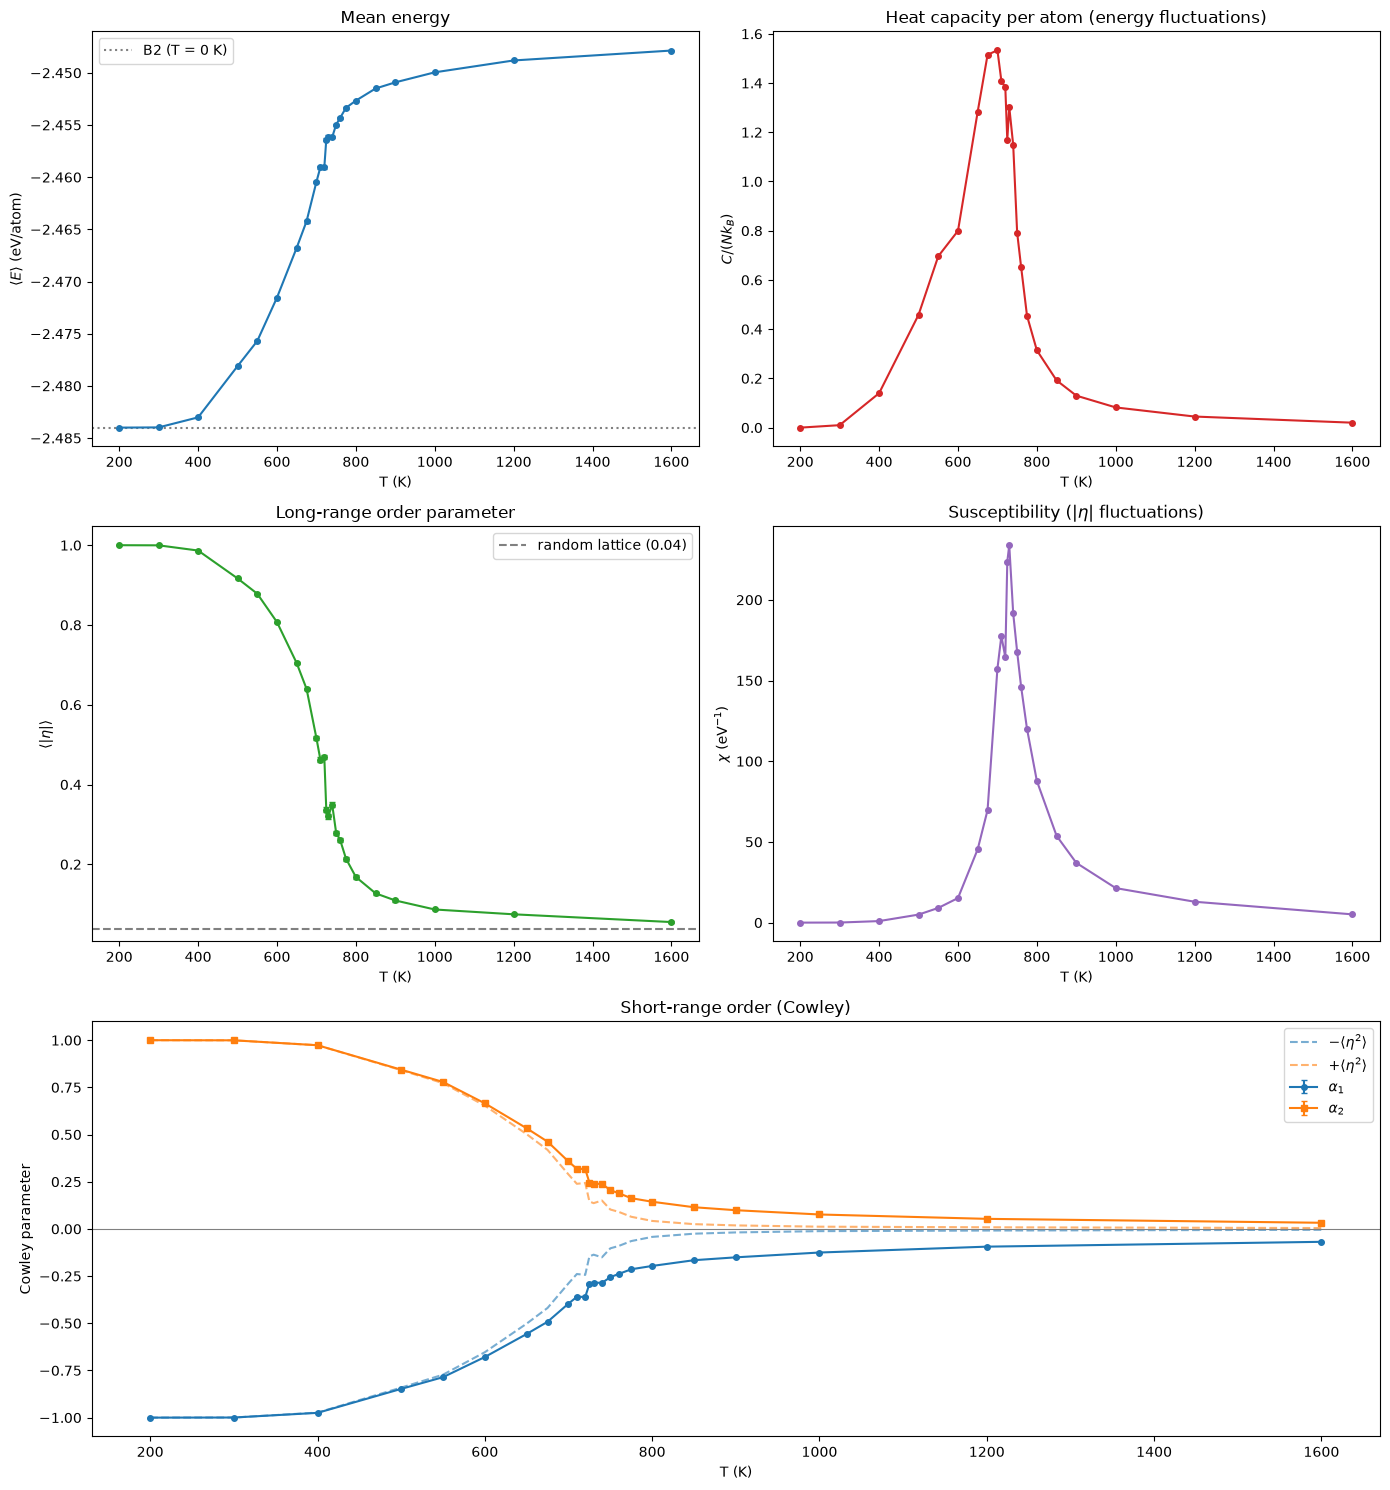

In [ ]:
fig, axes = plt.subplot_mosaic([["E", "C"], ["eta", "chi"], ["cowley", "cowley"]], figsize=(14, 15))

ax = axes["E"]
ax.errorbar(T_arr, E_mean, yerr=E_err, fmt="o-", ms=4, capsize=2)
ax.axhline(E0 / N, color="gray", ls=":", label="B2 (T = 0 K)")
ax.set_xlabel("T (K)")
ax.set_ylabel(r"$\langle E \rangle$ (eV/atom)")
ax.set_title("Mean energy")
ax.legend()

ax = axes["C"]
ax.plot(T_arr, C, "o-", ms=4, color="C3")
ax.set_xlabel("T (K)")
ax.set_ylabel(r"$C / (N k_B)$")
ax.set_title("Heat capacity per atom (energy fluctuations)")

ax = axes["eta"]
ax.errorbar(T_arr, eta_mean, yerr=eta_err, fmt="o-", ms=4, capsize=2, color="C2")
ax.axhline(eta_random, color="gray", ls="--", label=f"random lattice ({eta_random:.2f})")
ax.set_xlabel("T (K)")
ax.set_ylabel(r"$\langle |\eta| \rangle$")
ax.set_title("Long-range order parameter")
ax.legend()

ax = axes["chi"]
ax.plot(T_arr, chi, "o-", ms=4, color="C4")
ax.set_xlabel("T (K)")
ax.set_ylabel(r"$\chi$ (eV$^{-1}$)")
ax.set_title(r"Susceptibility ($|\eta|$ fluctuations)")

ax = axes["cowley"]
ax.errorbar(T_arr, alpha_1_mean, yerr=alpha_1_err, fmt="o-", ms=4, capsize=2, color="C0", label=r"$\alpha_1$")
ax.errorbar(T_arr, alpha_2_mean, yerr=alpha_2_err, fmt="s-", ms=4, capsize=2, color="C1", label=r"$\alpha_2$")
ax.plot(T_arr, -eta2_mean, "--", color="C0", alpha=0.6, label=r"$-\langle \eta^2 \rangle$")
ax.plot(T_arr, eta2_mean, "--", color="C1", alpha=0.6, label=r"$+\langle \eta^2 \rangle$")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("T (K)")
ax.set_ylabel("Cowley parameter")
ax.set_title("Short-range order (Cowley)")
ax.legend()

fig.tight_layout()
plt.show()

**Reading the Cowley plot.** If the only order in the crystal were the long-range order, a Cu on $\alpha$ would see a fraction $(1+\eta)/2$ of Zn on the $\beta$ sublattice, and a Cu on $\beta$ a fraction $(1-\eta)/2$. This gives $\alpha_1 = -\eta^2$ and $\alpha_2 = +\eta^2$ (dashed lines).
- Below $T_c$ the Cowley parameters follow these curves: the long-range order explains almost all of the local order.
- Above $T_c$, $\eta^2 \approx 0$ but $\alpha_1$ stays clearly negative: Cu atoms still prefer Zn first neighbours. This is **short-range order**, which survives the loss of long-range order and fades slowly as $T$ increases.

## 4. Transition temperature

Three estimates of $T_c$ from the scan:
- the maximum of the heat capacity;
- the maximum of the susceptibility $\chi$;
- the temperature where $\langle |\eta| \rangle$ drops the fastest (minimum of $d\langle|\eta|\rangle/dT$).

In [ ]:
Tc_C = T_arr[np.argmax(C)]
Tc_chi = T_arr[np.argmax(chi)]
Tc_eta = T_arr[np.argmin(np.gradient(eta_mean, T_arr))]
print(f"Tc from the heat capacity peak:      {Tc_C:.0f} K")
print(f"Tc from the susceptibility peak:     {Tc_chi:.0f} K")
print(f"Tc from the steepest drop of |eta|:  {Tc_eta:.0f} K")

Tc from the heat capacity peak:      700 K
Tc from the susceptibility peak:     730 K
Tc from the steepest drop of |eta|:  720 K


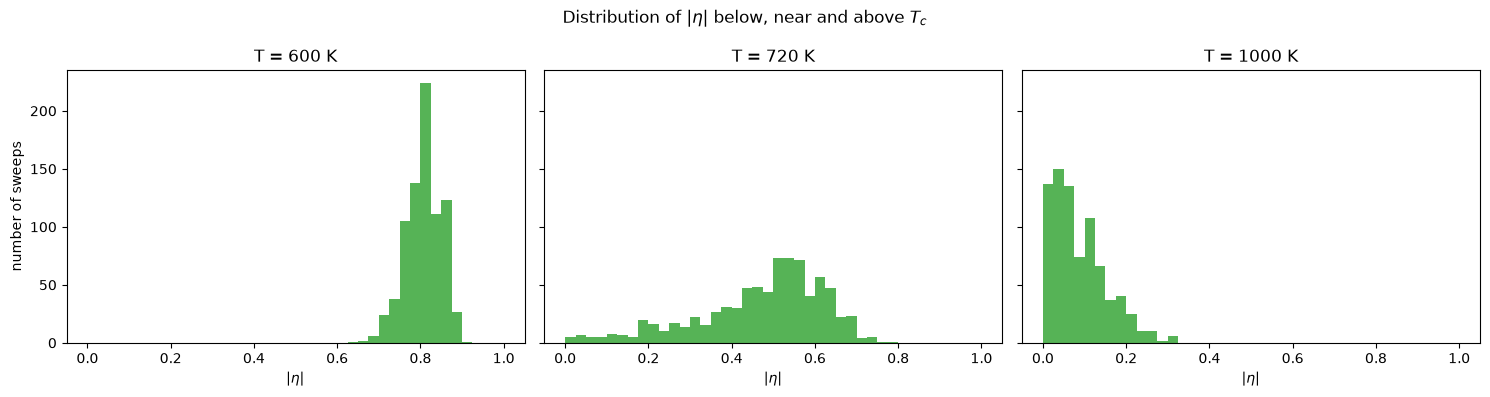

In [ ]:
T_hist = [600, int(Tc_eta), 1000]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, T in zip(axes, T_hist):
    ax.hist(series[T][1], bins=np.linspace(0, 1, 41), color="C2", alpha=0.8)
    ax.set_title(f"T = {T} K")
    ax.set_xlabel(r"$|\eta|$")
axes[0].set_ylabel("number of sweeps")
fig.suptitle(r"Distribution of $|\eta|$ below, near and above $T_c$")
fig.tight_layout()
plt.show()

Below $T_c$ the distribution is narrow around a large value of $|\eta|$ (ordered phase); above $T_c$ it is concentrated near the finite-size floor (disordered phase). Near $T_c$ it is very broad: the system wanders between ordered and disordered states, which is also why the heat capacity and the susceptibility are maximal there.

**Limits of these estimates.**
- The box is small ($L = 6$, 432 sites): the transition is rounded and slightly shifted, and $|\eta|$ never reaches 0.
- The temperature grid has a 25 K step around the transition, so $T_c$ is known to about $\pm 25$ K at best.
- Near $T_c$ the fluctuations are slow, so averages there are the least precise; longer runs or several independent runs would reduce the noise.
- The heat capacity is the noisiest quantity: it is the variance of a correlated series, so single points near $T_c$ can be off by 20-30 %, and the peak position moves by one or two grid points from run to run. For the final values, increase `N_MEAS` (e.g. 2000 or more), at least for the temperatures around the transition.

For comparison, the experimental order-disorder transition of $\beta$-brass is around 740 K.

In [ ]:
print(f"{'T (K)':>6} {'E (eV/atom)':>12} {'C/(N kB)':>9} {'<|eta|>':>8} {'chi (1/eV)':>11} {'alpha_1':>8} {'alpha_2':>8}")
for k, T in enumerate(T_SCAN):
    print(f"{T:6d} {E_mean[k]:12.4f} {C[k]:9.3f} {eta_mean[k]:8.3f} {chi[k]:11.1f} {alpha_1_mean[k]:+8.3f} {alpha_2_mean[k]:+8.3f}")

 T (K)  E (eV/atom)  C/(N kB)  <|eta|>  chi (1/eV)  alpha_1  alpha_2
   200      -2.4840     0.000    1.000         0.0   -1.000   +1.000
   300      -2.4840     0.010    1.000         0.1   -0.999   +0.999
   400      -2.4830     0.140    0.987         1.0   -0.975   +0.973
   500      -2.4781     0.458    0.917         5.0   -0.848   +0.844
   550      -2.4757     0.696    0.878         9.1   -0.786   +0.779
   600      -2.4715     0.800    0.807        15.2   -0.679   +0.666
   650      -2.4668     1.284    0.704        45.5   -0.557   +0.533
   675      -2.4642     1.515    0.640        69.7   -0.492   +0.462
   700      -2.4604     1.533    0.516       157.4   -0.396   +0.357
   710      -2.4590     1.409    0.462       177.6   -0.360   +0.318
   720      -2.4590     1.382    0.469       164.3   -0.360   +0.317
   725      -2.4564     1.168    0.337       223.6   -0.292   +0.246
   730      -2.4561     1.303    0.320       233.8   -0.284   +0.238
   740      -2.4562     1.148    0